# Import a Biacore Cycle/sample text export

Import **`biacore_cycle_sample.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it compares candidate fits and assesses their scientific limitations. No data download is required.

**Data origin:** [Duke TitrationAnalysis T200 example](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Chip%201%20Channel%202.txt). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src", repo_root / "notebooks"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "biacore_cycle_sample.tsv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: biacore_cycle_sample.tsv


## File layout and representative selection

Tab-separated pairs for cycles 20, 21, and 22 of the same AE.A244 series, selected to show clear responses. The verbatim labels are `50 µg`, `100 µ`, and `200 µ`. The original Windows-1252 text is converted to UTF-8; all finite time/response pairs are retained at their recorded sampling resolution.

These mass/truncated labels do not establish molar units. The reader receives verified concentrations explicitly from the companion sheet below. The source has eight incomplete or non-finite pairs in cycle 21. Only those eight pairs are omitted from this teaching export. There is no interpolation, smoothing or response correction.

The curve exports alone do not establish injection-event timing. The original
companion sample sheet now provides the phase timings used below.
The sensorgram plot rejoins all partitions on the original time grid.
Boundaries are seconds, and association is
`[association_start, association_end)`.

Concentrations are supplied explicitly from the original sample sheet.
`sample_id` is the analyte identity supplied by that sample sheet.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("biacore_cycle_sample")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id=fit_metadata["analyte"],
        concentrations=fit_metadata["concentrations"],
        concentration_unit="uM",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 3

Detected layout: spr_text
Imported 3 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Cycle:\\s*(?P<Cycle>\\d+)\\s+(?P<Sample_label>\\S+)\\s+(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())
plot_labels = header_info["Concentration_label"].tolist()

,Curve,Cycle,Sample_label,Concentration_label
0,Curve 1,20,AE.A244,50 µg
1,Curve 2,21,AE.A244,100 µ
2,Curve 3,22,AE.A244,200 µ


,Exported label
0,Cycle: 20 AE.A244 50 µg
1,Cycle: 21 AE.A244 100 µ
2,Cycle: 22 AE.A244 200 µ


## Verified concentration metadata

The original companion sample sheet supplies **molar concentrations**, independent
of the ambiguous export labels. The explicit mapping in `fit_metadata.json`
converts the author's values from M to µM. These concentrations are passed to the
reader; no molecular weight or interpretation of a truncated unit is guessed.
The fit section below displays the source and mapping.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].notna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,0.8868,AE.A244
1,Curve 2,1.7740,AE.A244
2,Curve 3,3.5470,AE.A244


## Plate information, when available

Cycle numbers and the `AE.A244` sample label do not establish plate coordinates. No plate layout is present in this text export.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Every finite source observation in the selected curves is plotted at its original
time. No resampling, smoothing or baseline subtraction is applied. Lines break
across gaps larger than three median sampling intervals. Legend entries use the
original concentration labels or cycle/flow-cell identifiers shown above.

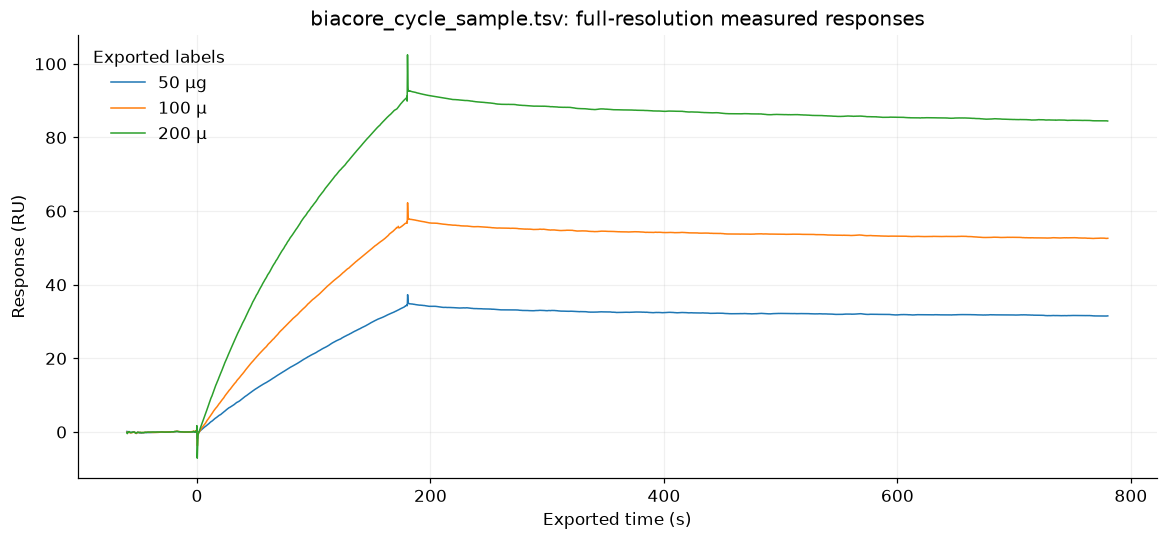

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axes = [ax]
for i, label in enumerate(plot_labels):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    breaks = np.flatnonzero(np.diff(time) > 3 * np.median(np.diff(time))) + 1
    segments = np.split(np.arange(len(time)), breaks)
    for axis in axes:
        for j, indices in enumerate(segments):
            axis.plot(time[indices], response[indices], color=f"C{i}", linewidth=1,
                      label=label if j == 0 else None)
for axis in axes:
    axis.set(xlabel="Exported time (s)", ylabel="Response (RU)")
    axis.legend(frameon=False, title="Exported labels")
    axis.grid(alpha=0.18)
ax.set_title("biacore_cycle_sample.tsv: full-resolution measured responses")
plt.show()

## Check the retained points and import partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. Duke phase times come from the companion metadata. The rstoolbox and
binning phase boundaries remain provisional. For binning, post-event data include
later protocol steps; the fit below uses only an explicitly limited early episode.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,601,1800,6003,8404,-60.06,780.24
1,Curve 2,600,1792,6003,8395,-59.96,780.24
2,Curve 3,600,1800,6002,8402,-59.96,780.14


,Name,Type,Start
0,Baseline,BASELINE,-60.06
1,Association,ASSOC,0.00
2,Dissociation,DISASSOC,180.00


All finite source observations in the teaching selections remain available in
the import. The fitting masks below leave transition regions out of the objective;
they do not remove observations from the experiment or shift the physical clock.
Source selection, omitted missing pairs and data licenses:
[SOURCES.md](data/spr_exports/SOURCES.md).

## Fitting setup and physical assumptions

The author sample sheet gives baseline −60–0 s, association 0–180 s,
and dissociation 180–780 s, with regeneration. Selected cycles 20–22 map to
All Concentrations entries 6–8: **0.8868, 1.774, 3.547 µM**. Analyte: AE.A244;
ligand: CH31. The `Bulkshift=Y` setting motivates one association-only RI term per
curve in **every** candidate, counted in BIC. Compare one-site, lumped transport,
heterogeneous ligand, and induced-fit models, with shared/per-curve Rmax.

In [8]:
display(pd.DataFrame({
    "Curve": curve_ids,
    "Fit concentration": fit_metadata["concentrations"] or ["unavailable"] * len(curve_ids),
    "Concentration unit": fit_metadata["concentration_unit"] or "not assigned",
}))
display(pd.Series({key: fit_metadata[key] for key in (
    "association_start", "association_end", "fit_end", "timing_verified",
    "molar_concentrations_verified", "regenerated", "bulk_shift", "initial_occupancy", "protocol"
)}).to_frame("Fit metadata"))
for source in fit_metadata["sources"]:
    print("Metadata/source:", source)

,Curve,Fit concentration,Concentration unit
0,Curve 1,0.8868,µM
1,Curve 2,1.7740,µM
2,Curve 3,3.5470,µM


,Fit metadata
association_start,0
association_end,180
fit_end,780
timing_verified,True
molar_concentrations_verified,True
regenerated,True
bulk_shift,True
initial_occupancy,zero after pre-injection background subtraction
protocol,Regenerated Biacore T200 cycles 20–22; metadat...


Metadata/source: https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Data%20Info%20Sheet.xlsx


## Align association, then compare candidate models

The notebook driver uses **pyKinGenie's forward binding functions** and SciPy
bounded least squares, with eight reproducible starting points (seed 2918).
It retains the true injection clock and propagates state at the physical switch,
including when transition points are masked. See [spr_fitting.py](spr_fitting.py).

Exclude 3 s around injection transitions; fit at most one original observation
per second, without averaging. Carterra's slower records retain their native
spacing. This reduces oversampling but does **not** establish independent errors.
Before fitting, make a copy and call
`fit_experiment.align_association(inplace=True, npoints=10)`. This subtracts
the mean of the last 10 baseline observations from every phase of each curve.
It changes response zeroes, not timestamps. The table below verifies that the
aligned pre-association mean is zero. The original `experiment` and raw plot
above remain unchanged. No additional median-baseline subtraction is applied
to the aligned fitting copy.

The removed offsets are recorded in `fit_metadata["association_alignment"]`.
For Carterra, the physical initial bound signal is reconstructed from the
aligned baseline plus its removed offset. Model predictions subtract the same
offset, so fitting uses aligned responses while preserving occupied initial
states. Fixed offset/initial estimates remain uncertain; the sensitivity
analysis does not make them exact.

Every candidate uses the same selected observations. BIC is
`n*log(RSS/n) + k*log(n)`; `k` includes rates, fractions, per-curve capacities and
RI terms. Lower BIC ranks these candidates **conditional on the noise/model
assumptions**. Reduced χ² here is `RSS/(n-k)` with unit variance; it is not a
calibrated chi-square goodness-of-fit test, and a value below 1 is not validation.

In [9]:
from copy import deepcopy
from spr_fitting import run_analysis, parameter_table, plot_fit, trust_assessment

# Preserve the imported experiment and explicitly align every fitting curve.
fit_experiment = deepcopy(experiment)
association_step = int(experiment.df_steps.index[experiment.df_steps["Type"] == "ASSOC"][0])
alignment_points = 10
alignment_offsets = {
    name: float(np.mean(experiment.ys[i][association_step - 1][-alignment_points:]))
    for i, name in enumerate(experiment.sensor_names)
}
fit_experiment.align_association(inplace=True, npoints=alignment_points)
fit_metadata = deepcopy(fit_metadata)
fit_metadata["association_alignment"] = {
    "method": "align_association",
    "npoints": alignment_points,
    "offsets_by_sensor": alignment_offsets,
}
aligned_baseline_means = [
    float(np.mean(fit_experiment.ys[i][association_step - 1][-alignment_points:]))
    for i in range(fit_experiment.no_sensors)
]
assert np.allclose(aligned_baseline_means, 0, atol=1e-10)
display(pd.DataFrame({
    "Curve": curve_ids,
    "Subtracted pre-association mean": list(alignment_offsets.values()),
    "Aligned pre-association mean": aligned_baseline_means,
}))

analysis = run_analysis(fit_experiment, fit_metadata, n_starts=8, sensitivity=True)
display(analysis["comparison"].style.format(precision=4, na_rep="not identified"))
if not analysis["failures"].empty:
    display(analysis["failures"])

# Optional: export the numerical audit report with
# from spr_fitting import save_report
# save_report(analysis, "my_fit_report.json", data_file.stem)

,Curve,Subtracted pre-association mean,Aligned pre-association mean
0,Curve 1,0.041200,2.775558e-18
1,Curve 2,0.302471,2.220446e-17
2,Curve 3,0.481542,-8.881784e-17


,Model,Rmax,Parameters,Points,Reduced χ² (unit variance),RMSE,BIC,ΔBIC,Jacobian condition,Max |parameter correlation|,Near bounds,Converged starts
0,heterogeneous,local,11,2313,0.0160,0.1263,-9488.1827,0.0000,277.5923,0.9972,,8/8
1,induced_fit,local,10,2313,0.0179,0.1336,-9233.6993,254.4834,225.9959,0.9987,,8/8
2,one_site,local,8,2313,0.1835,0.4277,-3867.4121,5620.7707,101.9753,0.9976,,8/8
3,mass_transport,local,9,2313,0.1836,0.4277,-3859.6632,5628.5195,330.3182,0.9960,Ktr,8/8
4,heterogeneous,shared,9,2313,0.2882,0.5358,-2816.9128,6671.2700,7489.5370,0.9989,,8/8
5,induced_fit,shared,8,2313,0.6703,0.8173,-871.1628,8617.0200,151.9976,0.9628,,8/8
6,one_site,shared,6,2313,0.8465,0.9189,-345.0241,9143.1587,77.2092,0.9834,,8/8
7,mass_transport,shared,7,2313,0.8469,0.9189,-337.2471,9150.9356,176.5214,0.9861,Ktr,8/8


## Lowest-BIC fit and residuals

Thin solid lines are the association-aligned data; dashed lines are the selected fitted
curves. Grey bands indicate excluded transition regions. The residual panel is
essential: an excellent-looking overlay can still have long systematic errors.
For binning, this figure shows only the fitted early episode.

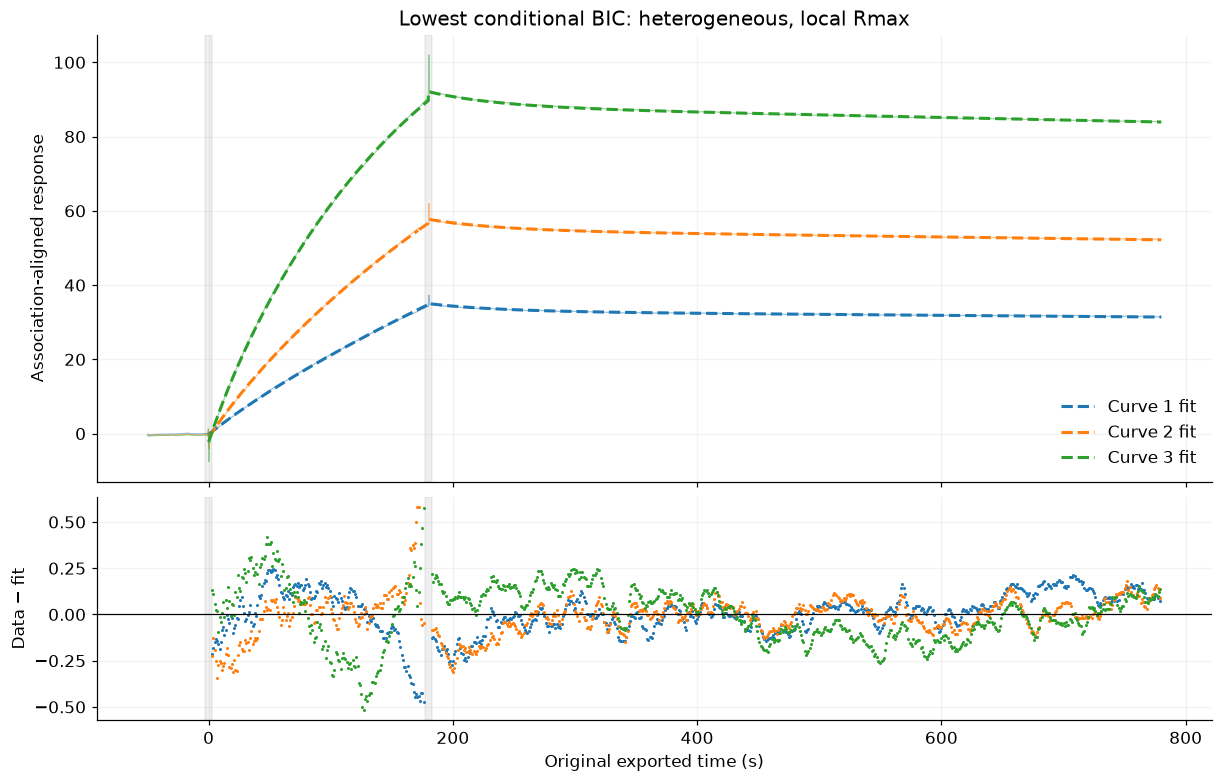

In [10]:
fig_fit = plot_fit(analysis)
plt.show()

## Parameters and identifiability

Intervals below are **nominal local iid least-squares intervals**, conditional
on the chosen model, fixed baseline/initial signal, event times and input
concentrations. Correlated residuals or model mismatch make them overconfident.
They are not bootstrap/profile intervals or proof of a molecular mechanism.
Derived `k_on = k_off/Kd` entries are point estimates; no interval is claimed.
Extreme intervals, near-unit correlations and near-bound parameters indicate
that individual parameters should not be interpreted.

In [11]:
display(parameter_table(analysis).style.format({
    "Estimate": "{:.4g}", "Conditional 95% lower": "{:.4g}",
    "Conditional 95% upper": "{:.4g}",
}, na_rep="not profiled/identified"))
display(analysis["best"]["correlation"].style.format(precision=3, na_rep="not identified"))
display(analysis["best"]["residuals"].style.format(precision=4))

,Parameter,Unit,Estimate,Conditional 95% lower,Conditional 95% upper
0,Kd1,µM,0.04901,0.04832,0.0497
1,k_off1,1/s,8.063e-05,7.957e-05,8.171e-05
2,Kd2,µM,1.862,1.785,1.942
3,k_off2,1/s,0.01735,0.01687,0.01784
4,fraction,dimensionless,0.9571,0.9562,0.958
5,Rmax_1,RU,150,149.2,150.8
6,Rmax_2,RU,141,140.3,141.6
7,Rmax_3,RU,142.4,141.9,142.9
8,RI_1,RU,-0.2266,-0.2632,-0.1901
9,RI_2,RU,-1.029,-1.073,-0.9858


,Kd1,k_off1,Kd2,k_off2,fraction,Rmax_1,Rmax_2,Rmax_3,RI_1,RI_2,RI_3
Kd1,1.000,0.910,0.133,0.700,0.117,0.399,0.404,0.417,-0.199,-0.179,-0.052
k_off1,0.910,1.000,0.115,0.714,0.133,-0.006,0.000,0.021,-0.191,-0.252,-0.297
Kd2,0.133,0.115,1.000,0.282,-0.829,0.239,0.252,0.300,0.435,0.256,-0.093
k_off2,0.700,0.714,0.282,1.000,-0.275,0.194,0.207,0.244,-0.426,-0.538,-0.539
fraction,0.117,0.133,-0.829,-0.275,1.000,-0.206,-0.223,-0.278,-0.098,0.117,0.397
Rmax_1,0.399,-0.006,0.239,0.194,-0.206,1.000,0.997,0.994,-0.049,0.096,0.432
Rmax_2,0.404,0.000,0.252,0.207,-0.223,0.997,1.000,0.997,-0.044,0.080,0.417
Rmax_3,0.417,0.021,0.300,0.244,-0.278,0.994,0.997,1.000,-0.048,0.064,0.370
RI_1,-0.199,-0.191,0.435,-0.426,-0.098,-0.049,-0.044,-0.048,1.000,0.708,0.468
RI_2,-0.179,-0.252,0.256,-0.538,0.117,0.096,0.080,0.064,0.708,1.000,0.694


,Curve,Points,RMSE,Lag-1 residual correlation,Baseline noise estimate,RMSE / baseline noise
0,Cycle: 20 AE.A244 50 µg,771,0.1158,0.9824,0.0193,6.0129
1,Cycle: 21 AE.A244 100 µ,771,0.1031,0.9546,0.0180,5.7241
2,Cycle: 22 AE.A244 200 µ,771,0.1542,0.9808,0.0235,6.5486


## Sensitivity of the selected model

Refit the selected family after changing trimming, sampling interval,
dissociation-window length and event times. Parameter entries are **ratios to
the primary fit**: 1 means unchanged, 1.5 means 50% higher. These runs use different
observations, so their BIC values would not be directly comparable. A fitting
failure is reported, not treated as a biological finding.

In [12]:
display(analysis["sensitivity"].style.format(precision=4, na_rep="—"))

,Perturbation,RMSE,Kd1,k_off1,Kd2,k_off2,fraction
0,trim 6 s,0.1238,0.9897,0.9960,0.9845,0.9820,1.0004
1,trim 10 s,0.1194,0.9781,0.9891,0.9546,0.9507,1.0015
2,5 s observation spacing,0.1268,1.0030,1.0027,1.0037,1.0111,0.9997
3,half dissociation window,0.1333,1.2180,1.2303,0.9251,1.1561,1.0046
4,event times -1 s,0.1230,1.0008,0.9970,1.2710,1.0118,0.9929
5,event times +1 s,0.1356,0.9969,1.0030,0.7837,0.9903,1.0057


## Decision: can the final fit be trusted?

The decision below separates a descriptive curve fit from validated intrinsic
kinetic constants. It uses the residuals, parameter coupling, available metadata
and sensitivity checks, not BIC or optimizer convergence alone.

In [13]:
from IPython.display import Markdown

assessment = trust_assessment("biacore_cycle_sample", analysis)
display(Markdown("**" + assessment["Verdict"] + "**"))
for reason in assessment["Reasons"]:
    display(Markdown("- " + reason))

**Good descriptive fit; the two-population mechanism and nominal precision are not validated.**

- Molar concentrations and event durations come from the original sample sheet; association-only RI terms are fitted and counted.

- The local-capacity two-population model wins among the tested models, but its residuals remain strongly correlated and exceed baseline noise.

- Halving dissociation changes the dominant Kd by 22% and koff by 23%; shifting events -1 s changes the minor-population Kd by 27%.

- Treat the dominant slow component as provisional. Do not infer two molecular site classes or quote the iid least-squares intervals as validated uncertainty.

Detailed methods, source metadata and cross-notebook conclusions:
[SPR_FITTING.md](SPR_FITTING.md).

Scientific context: [Cytiva kinetics/affinity application guide](https://cdn.cytivalifesciences.com/api/public/content/digi-33041-pdf)
and [Schuck & Zhao, mass transport and surface heterogeneity](https://pmc.ncbi.nlm.nih.gov/articles/PMC4134667/).
Statistical improvement alone does not identify a physical mechanism; experimental
controls and identifiability must support a kinetic interpretation.